# TP : Apprentissage automatique appliqué à l'approbation de crédit

## Objectifs

Dans ce TP, on va :

1. dire de quel type d'apprentissage il s'agit ;
2. charger les données et les explorer avec des graphiques ;
3. préparer les données (valeurs manquantes, variables texte, mise à l'échelle) ;
4. entraîner plusieurs modèles et les comparer ;
5. évaluer le meilleur modèle ;
6. interpréter les résultats.

## 1. Type d'apprentissage

**Le problème :** à partir des informations d'une demande de carte de crédit, on veut prédire si la demande est **accordée (+)** ou **refusée (−)**.

C'est de l'**apprentissage supervisé** : pour chaque demande, on connaît déjà la bonne réponse (accordée ou refusée). Le modèle apprend à partir de ces exemples.

C'est une **classification binaire** : la réponse n'a que deux valeurs possibles (accordé ou refusé).

- Si on voulait prédire un nombre (par exemple le montant du crédit), ce serait une **régression**.
- Si on n'avait pas la décision et qu'on cherchait juste des groupes de clients, ce serait de l'**apprentissage non supervisé**.

## 2. Le jeu de données

Le jeu de données **Credit Approval** (UCI) contient **690 demandes de crédit** et **15 variables**, plus la décision (A16).

Les noms des variables ont été **cachés pour des raisons de confidentialité** : elles s'appellent A1 à A16. On connaît leur type, mais pas leur signification.

| Variable | Type | Valeurs |
|---|---|---|
| A1 | texte | b, a |
| A2 | nombre | continu |
| A3 | nombre | continu |
| A4 | texte | u, y, l, t |
| A5 | texte | g, p, gg |
| A6 | texte | 14 valeurs possibles |
| A7 | texte | 9 valeurs possibles |
| A8 | nombre | continu |
| A9 | texte | t, f |
| A10 | texte | t, f |
| A11 | nombre | entier |
| A12 | texte | t, f |
| A13 | texte | g, p, s |
| A14 | nombre | continu |
| A15 | nombre | continu |
| **A16** | **décision (cible)** | + accordé, − refusé |

Le fichier `crx.data` doit être dans le même dossier que le notebook. Les valeurs manquantes y sont notées `?`.

In [22]:
# Importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, learning_curve, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, confusion_matrix,
                             classification_report, RocCurveDisplay)

# Reproductibilité et style des graphiques
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

In [23]:
# Chargement du jeu de données : fichier local, sinon URL de l'UCI
colonnes = [f"A{i}" for i in range(1, 17)]
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/credit-screening/crx.data"

try:
    df = pd.read_csv("crx.data", header=None, names=colonnes, na_values="?")
except FileNotFoundError:
    df = pd.read_csv(URL, header=None, names=colonnes, na_values="?")

# Cible lisible pour les graphiques
df["decision"] = df["A16"].map({"+": "Accordé", "-": "Refusé"})

print("Dimensions :", df.shape)
df.head()

Dimensions : (690, 17)


,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14,A15,A16,decision
0,b,30.83,0.000,u,g,w,v,1.25,t,t,1,f,g,202.0,0,+,Accordé
1,a,58.67,4.460,u,g,q,h,3.04,t,t,6,f,g,43.0,560,+,Accordé
2,a,24.50,0.500,u,g,q,h,1.50,t,f,0,f,g,280.0,824,+,Accordé
3,b,27.83,1.540,u,g,w,v,3.75,t,t,5,t,g,100.0,3,+,Accordé
4,b,20.17,5.625,u,g,w,v,1.71,t,f,0,f,s,120.0,0,+,Accordé


## 3. Première exploration

On regarde d'abord les types de colonnes, les valeurs manquantes et quelques statistiques.

In [24]:
# Types des colonnes et nombre de valeurs non renseignées
df.info()
print("\nValeurs manquantes par colonne :")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nDemandes avec au moins une valeur manquante :", df.isna().any(axis=1).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 17 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   A1        678 non-null    object 
 1   A2        678 non-null    float64
 2   A3        690 non-null    float64
 3   A4        684 non-null    object 
 4   A5        684 non-null    object 
 5   A6        681 non-null    object 
 6   A7        681 non-null    object 
 7   A8        690 non-null    float64
 8   A9        690 non-null    object 
 9   A10       690 non-null    object 
 10  A11       690 non-null    int64  
 11  A12       690 non-null    object 
 12  A13       690 non-null    object 
 13  A14       677 non-null    float64
 14  A15       690 non-null    int64  
 15  A16       690 non-null    object 
 16  decision  690 non-null    object 
dtypes: float64(4), int64(2), object(11)
memory usage: 91.8+ KB

Valeurs manquantes par colonne :
A1     12
A2     12
A4      6
A5      6
A6      9
A7    

In [25]:
# Statistiques descriptives des variables numériques
variables_num = ["A2", "A3", "A8", "A11", "A14", "A15"]
variables_cat = ["A1", "A4", "A5", "A6", "A7", "A9", "A10", "A12", "A13"]
df[variables_num].describe().round(1)

,A2,A3,A8,A11,A14,A15
count,678.0,690.0,690.0,690.0,677.0,690.0
mean,31.6,4.8,2.2,2.4,184.0,1017.4
std,12.0,5.0,3.3,4.9,173.8,5210.1
min,13.8,0.0,0.0,0.0,0.0,0.0
25%,22.6,1.0,0.2,0.0,75.0,0.0
50%,28.5,2.8,1.0,0.0,160.0,5.0
75%,38.2,7.2,2.6,3.0,276.0,395.5
max,80.2,28.0,28.5,67.0,2000.0,100000.0


**Ce qu'on observe :**

- 37 demandes sur 690 (environ 5 %) ont une valeur manquante.
- Les variables n'ont pas du tout la même échelle : A2 va de 14 à 80, alors que A15 va de 0 à 100 000.
- Certaines variables ont quelques valeurs très grandes (pour A15, la moyenne est de 1 017 mais la médiane n'est que de 5).

Il faudra donc **mettre les variables à la même échelle** avant d'entraîner les modèles.

## 4. Visualisation des données

### 4.1 Répartition des décisions

On vérifie s'il y a à peu près autant de crédits accordés que refusés.

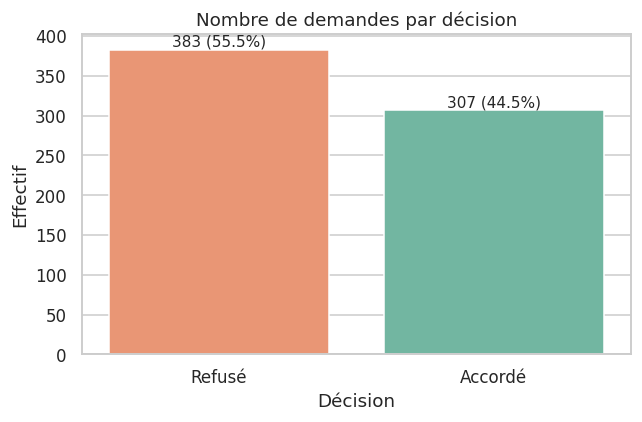

In [26]:
# Diagramme en barres du nombre de demandes par décision
fig, ax = plt.subplots(figsize=(6, 4))
ordre = df["decision"].value_counts().index
sns.countplot(data=df, x="decision", order=ordre, hue="decision", legend=False, ax=ax)
for patch in ax.patches:
    hauteur = int(patch.get_height())
    ax.annotate(f"{hauteur} ({hauteur / len(df):.1%})",
                (patch.get_x() + patch.get_width() / 2, hauteur),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Nombre de demandes par décision")
ax.set_xlabel("Décision")
ax.set_ylabel("Effectif")
plt.tight_layout()
plt.show()

**Ce qu'on observe :** 383 refus (55,5 %) et 307 accords (44,5 %). Les deux classes sont à peu près équilibrées.

Un modèle qui refuserait tout le monde aurait déjà 55,5 % de bonnes réponses. **Nos modèles devront faire mieux que ça.**

### 4.2 Variables numériques selon la décision

On compare la distribution de chaque variable numérique chez les accordés et chez les refusés. Plus les deux courbes sont éloignées, plus la variable est utile. Certaines variables sont affichées en échelle log pour être plus lisibles.

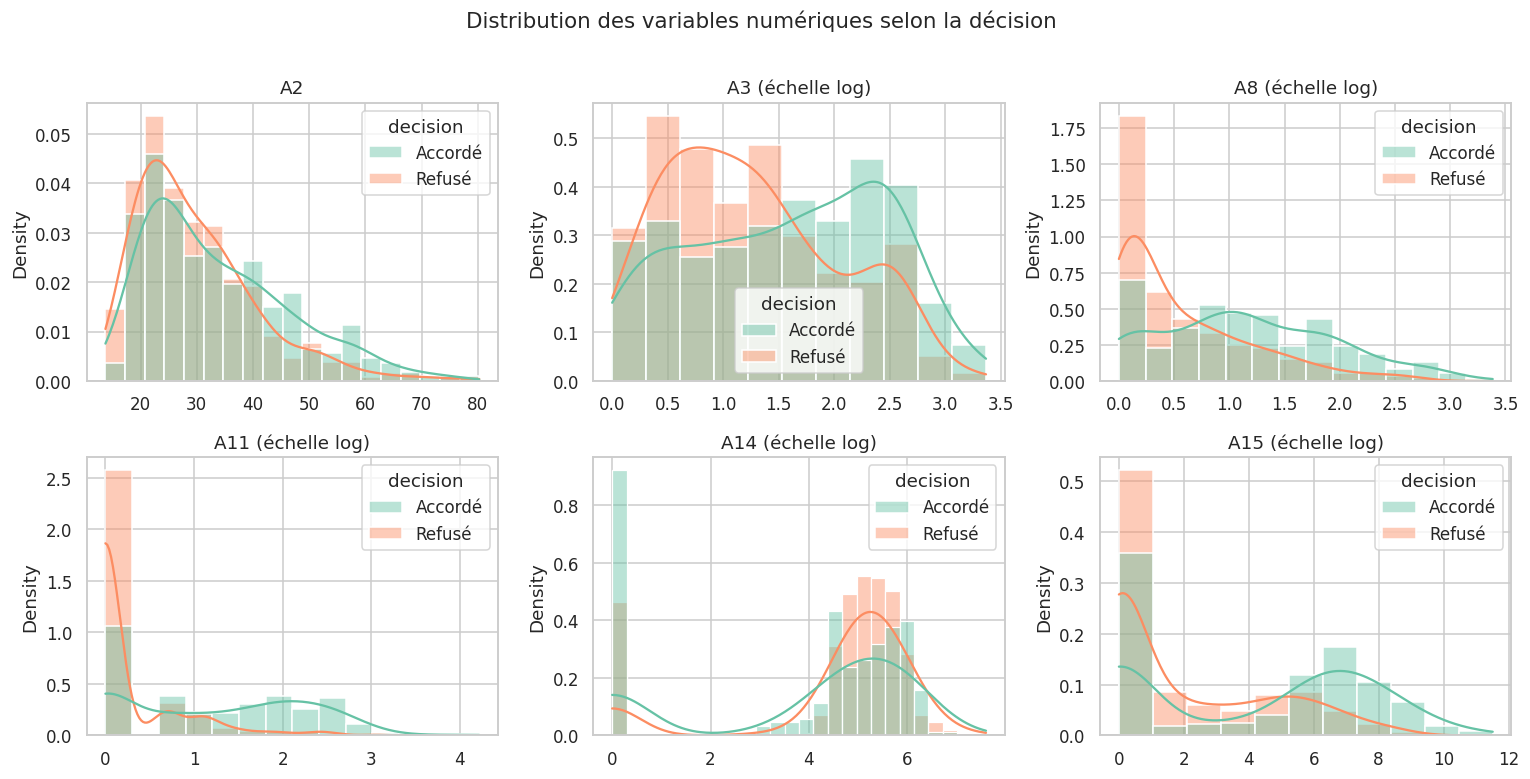

,A2,A3,A8,A11,A14,A15
decision,,,,,,
Accordé,30.50,4.46,2.00,3.0,120.0,221.0
Refusé,27.33,2.21,0.42,0.0,167.5,1.0


In [27]:
# Histogrammes superposés des six variables numériques, par décision
asymetriques = ["A3", "A8", "A11", "A14", "A15"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, var in zip(axes.ravel(), variables_num):
    valeurs = np.log1p(df[var]) if var in asymetriques else df[var]
    sns.histplot(x=valeurs, hue=df["decision"], kde=True, alpha=0.45,
                 stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{var} (échelle log)" if var in asymetriques else var)
    ax.set_xlabel("")
plt.suptitle("Distribution des variables numériques selon la décision", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Médianes par décision, pour chiffrer les écarts
df.groupby("decision")[variables_num].median().round(2)

**Ce qu'on observe :**

- **A8, A11 et A15** sont plus élevées chez les accordés (par exemple, la médiane d'A11 est de 3 chez les accordés et de 0 chez les refusés).
- **A3** va dans le même sens, mais avec un écart plus faible.
- **A2** et **A14** font peu de différence entre les deux groupes.

### 4.3 Variables texte et taux d'accord

Pour chaque variable texte, on calcule le pourcentage de crédits accordés pour chaque valeur.

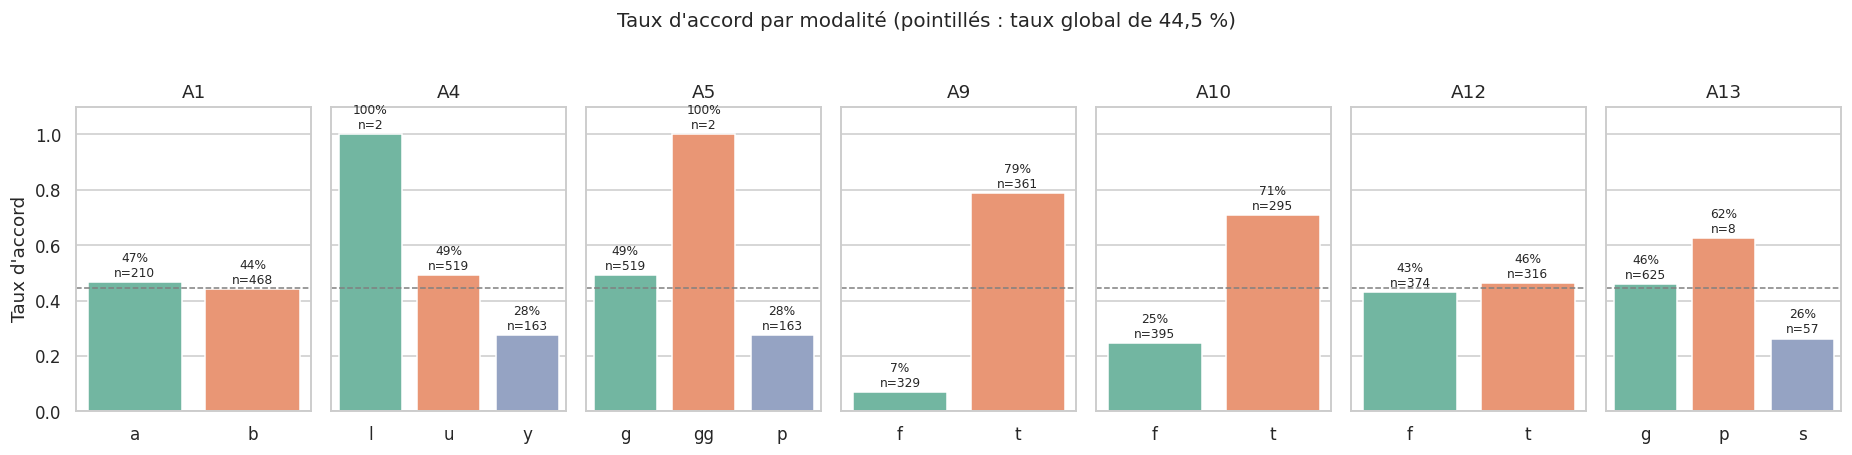

In [28]:
# Taux d'accord par modalité, pour les variables catégorielles à peu de modalités
cat_courtes = ["A1", "A4", "A5", "A9", "A10", "A12", "A13"]
taux_global = (df["A16"] == "+").mean()

fig, axes = plt.subplots(1, len(cat_courtes), figsize=(17, 4), sharey=True)
for ax, var in zip(axes, cat_courtes):
    taux = df.groupby(var)["A16"].apply(lambda s: (s == "+").mean())
    effectifs = df[var].value_counts()
    sns.barplot(x=taux.index, y=taux.values, hue=taux.index, legend=False, ax=ax)
    for i, (modalite, t) in enumerate(taux.items()):
        ax.text(i, t + 0.02, f"{t:.0%}\nn={effectifs[modalite]}", ha="center", fontsize=8)
    ax.axhline(taux_global, color="grey", linestyle="--", linewidth=1)
    ax.set_title(var)
    ax.set_xlabel("")
    ax.set_ylim(0, 1.1)
axes[0].set_ylabel("Taux d'accord")
plt.suptitle("Taux d'accord par modalité (pointillés : taux global de 44,5 %)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

**Ce qu'on observe :**

- **A9 est la variable la plus importante** : quand A9 = t, 79 % des demandes sont accordées ; quand A9 = f, seulement 7 %.
- **A10** est aussi utile (71 % contre 25 %).
- Les autres variables changent peu le taux d'accord.

### 4.4 Relation entre deux variables

On place chaque demande sur un graphique selon A8 et A11, avec une couleur par décision.

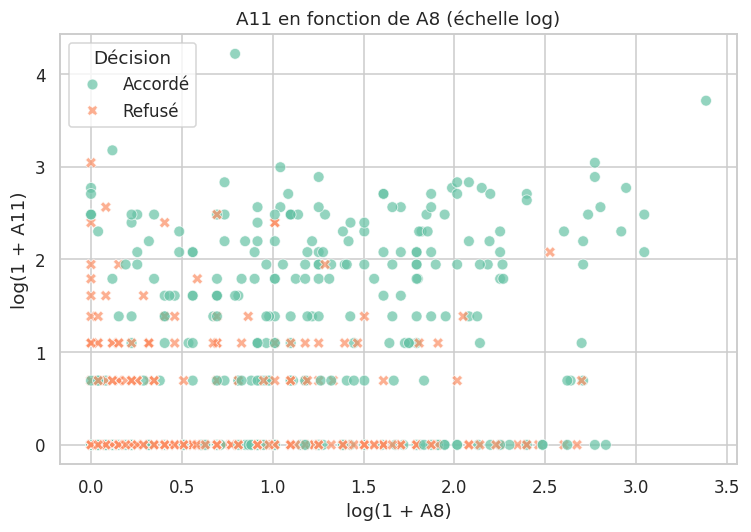

In [29]:
# Nuage de points : A11 en fonction de A8 (échelle log)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=np.log1p(df["A8"]), y=np.log1p(df["A11"]), hue=df["decision"],
                style=df["decision"], s=50, alpha=0.7, ax=ax)
ax.set_title("A11 en fonction de A8 (échelle log)")
ax.set_xlabel("log(1 + A8)")
ax.set_ylabel("log(1 + A11)")
ax.legend(title="Décision")
plt.tight_layout()
plt.show()

**Ce qu'on observe :** les accordés sont plutôt en haut à droite, mais les deux groupes se mélangent beaucoup. Deux variables ne suffisent pas : le modèle devra utiliser toutes les variables.

### 4.5 Boîtes à moustaches et corrélations

Les boîtes à moustaches montrent la médiane et la dispersion. La matrice de corrélation montre si deux variables donnent la même information.

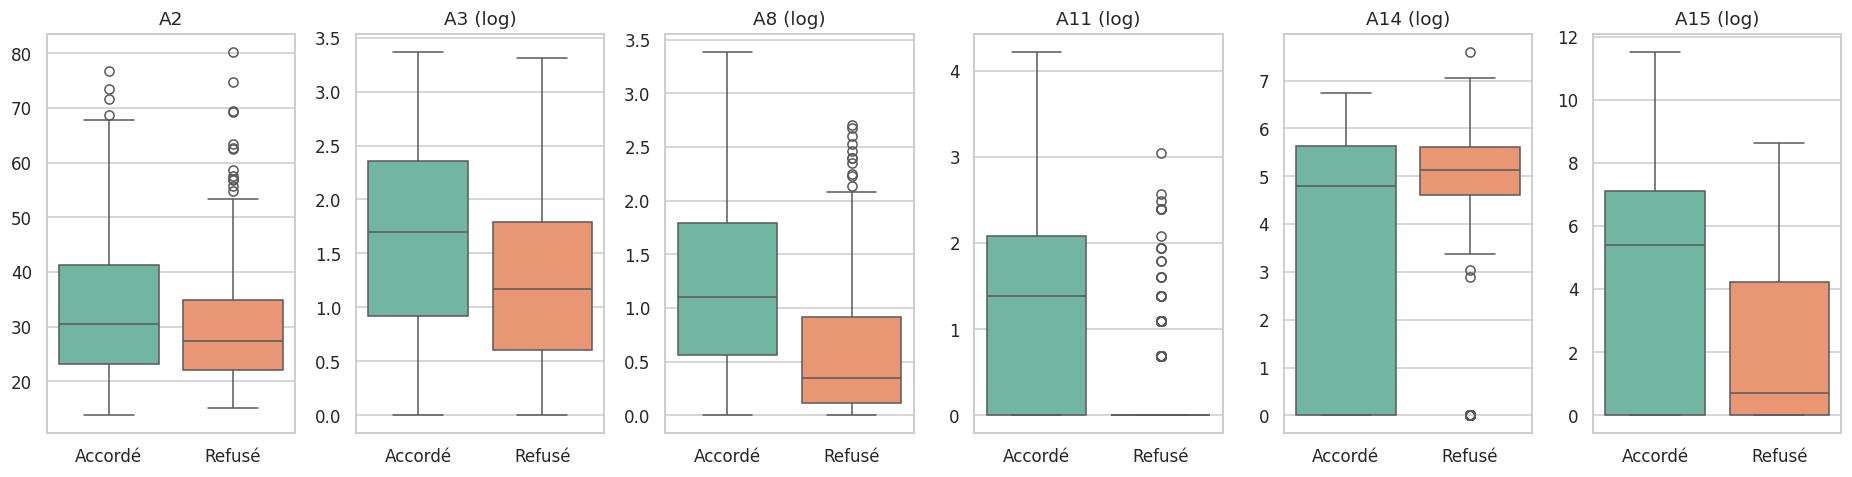

In [30]:
# Boîtes à moustaches par décision (échelle log pour les variables asymétriques)
fig, axes = plt.subplots(1, 6, figsize=(17, 4.5))
for ax, var in zip(axes, variables_num):
    valeurs = np.log1p(df[var]) if var in asymetriques else df[var]
    sns.boxplot(x=df["decision"], y=valeurs, hue=df["decision"], legend=False, ax=ax)
    ax.set_title(f"{var} (log)" if var in asymetriques else var)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

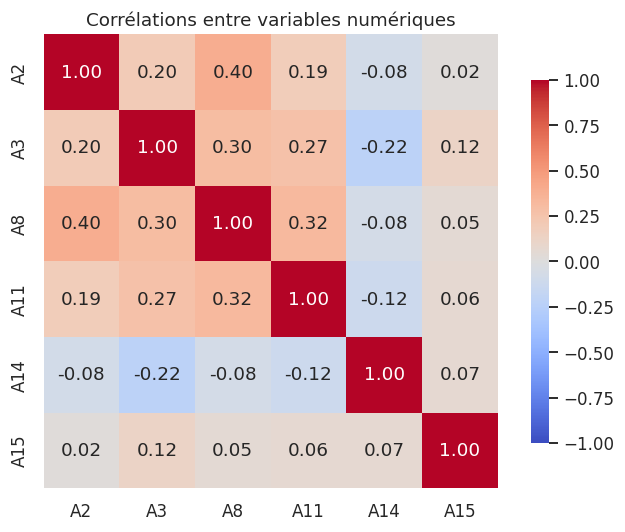

In [31]:
# Matrice de corrélation des variables numériques
fig, ax = plt.subplots(figsize=(6.5, 5))
corr = df[variables_num].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Corrélations entre variables numériques")
plt.tight_layout()
plt.show()

**Ce qu'on observe :**

- Les boîtes à moustaches confirment l'écart entre accordés et refusés pour A8, A11 et A15.
- Les corrélations sont faibles (la plus forte est de 0,40 entre A2 et A8). Les variables apportent donc des informations différentes.

## 5. Préparation des données

Avant d'entraîner les modèles, on prépare les données :

1. **On sépare les données** : 75 % pour l'entraînement, 25 % pour le test. Le test sert uniquement à la fin.
2. **On remplace les valeurs manquantes** : par la médiane pour les nombres, par la valeur la plus fréquente pour le texte.
3. **On transforme le texte en nombres** : chaque valeur devient une colonne de 0 et de 1 (*one-hot encoding*).
4. **On met les nombres à la même échelle** (standardisation).

Tout est regroupé dans un **pipeline**, ce qui garantit que les mêmes étapes sont appliquées partout, sans utiliser les données de test.

In [32]:
# 1) Séparation entrées / cible (1 = accordé, 0 = refusé)
X = df.drop(columns=["A16", "decision"])
y = (df["A16"] == "+").astype(int)
noms_classes = ["Refusé", "Accordé"]   # dans l'ordre 0, 1

# 2) Découpage stratifié : 75 % entraînement, 25 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Entraînement :", X_train.shape[0], "| Test :", X_test.shape[0])
print("Taux d'accord dans l'entraînement :", round(y_train.mean(), 3))
print("Taux d'accord dans le test :", round(y_test.mean(), 3))

# 3) Prétraitement : imputation + standardisation (numériques), imputation + encodage (catégorielles)
pretraitement_num = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("echelle", StandardScaler()),
])
pretraitement_cat = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OneHotEncoder(handle_unknown="ignore")),
])
preprocesseur = ColumnTransformer([
    ("num", pretraitement_num, variables_num),
    ("cat", pretraitement_cat, variables_cat),
])

Entraînement : 517 | Test : 173
Taux d'accord dans l'entraînement : 0.445
Taux d'accord dans le test : 0.445


## 6. Comparaison des modèles

On compare 5 modèles, du plus simple au plus complexe :

- une **référence** qui refuse toujours (elle ne regarde pas les données) ;
- la **régression logistique** ;
- les **k plus proches voisins** ;
- l'**arbre de décision** ;
- la **forêt aléatoire**.

On utilise une **validation croisée à 5 plis** : les données d'entraînement sont coupées en 5 parties, et chaque partie sert une fois à tester le modèle.

On regarde deux indicateurs :

- l'**exactitude** : le pourcentage de bonnes réponses ;
- l'**AUC** : entre 0,5 (hasard) et 1 (parfait), elle mesure si le modèle sait distinguer un bon dossier d'un mauvais.

In [33]:
# Modèles candidats, chacun précédé du même prétraitement
modeles = {
    "Référence (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(max_iter=1000),
    "K plus proches voisins (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Arbre de décision": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=200, random_state=42),
}

pipelines = {nom: Pipeline([("prep", preprocesseur), ("modele", m)])
             for nom, m in modeles.items()}

validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultats = []
for nom, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=validation, scoring=["accuracy", "roc_auc"])
    resultats.append({"Modèle": nom,
                      "Exactitude moyenne": scores["test_accuracy"].mean(),
                      "Écart-type": scores["test_accuracy"].std(),
                      "AUC moyenne": scores["test_roc_auc"].mean()})

tableau = pd.DataFrame(resultats).sort_values("Exactitude moyenne", ascending=False).reset_index(drop=True)
tableau.round(3)

,Modèle,Exactitude moyenne,Écart-type,AUC moyenne
0,Forêt aléatoire,0.876,0.027,0.925
1,Régression logistique,0.849,0.030,0.916
2,K plus proches voisins (k=5),0.830,0.014,0.893
3,Arbre de décision,0.816,0.020,0.879
4,Référence (classe majoritaire),0.555,0.002,0.500


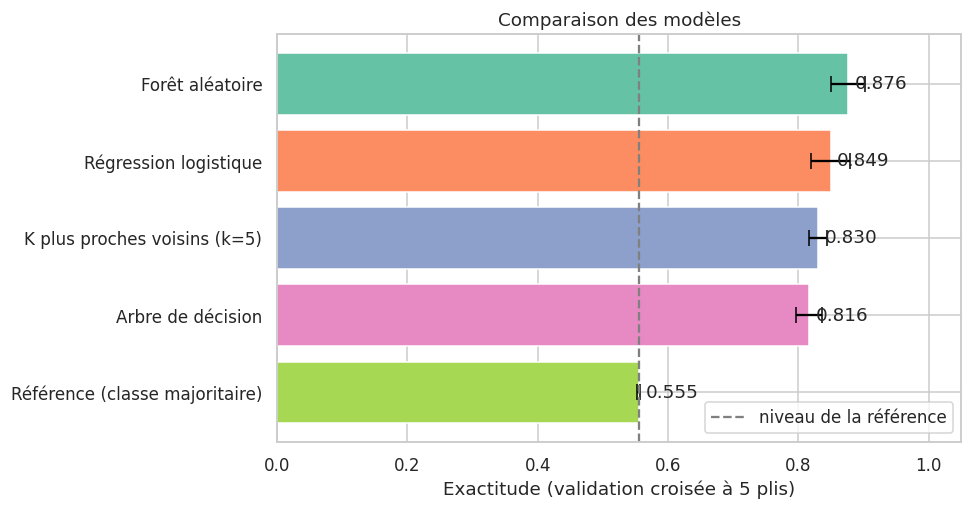

In [34]:
# Graphique : exactitude moyenne en validation croisée, avec barres d'erreur
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(tableau["Modèle"], tableau["Exactitude moyenne"],
        xerr=tableau["Écart-type"], capsize=5, color=sns.color_palette("Set2", len(tableau)))
ax.set_xlim(0, 1.05)
ax.invert_yaxis()
ax.axvline(tableau.loc[tableau["Modèle"].str.startswith("Référence"), "Exactitude moyenne"].values[0],
           color="grey", linestyle="--", label="niveau de la référence")
for i, val in enumerate(tableau["Exactitude moyenne"]):
    ax.text(val + 0.01, i, f"{val:.3f}", va="center")
ax.set_xlabel("Exactitude (validation croisée à 5 plis)")
ax.set_title("Comparaison des modèles")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Ce qu'on observe :**

- La référence obtient 0,555 : elle refuse tout le monde.
- Tous les vrais modèles font beaucoup mieux.
- **La forêt aléatoire est la meilleure** (environ 88 % d'exactitude), devant la régression logistique (environ 85 %).

## 7. Évaluation finale sur le jeu de test

On entraîne le meilleur modèle sur toutes les données d'entraînement, puis on le teste **une seule fois** sur les données de test.

In [35]:
# Sélection du meilleur modèle selon la validation croisée
meilleur_nom = tableau.iloc[0]["Modèle"]
meilleur_pipe = pipelines[meilleur_nom]
meilleur_pipe.fit(X_train, y_train)
y_pred = meilleur_pipe.predict(X_test)
y_proba = meilleur_pipe.predict_proba(X_test)[:, 1]

print("Meilleur modèle :", meilleur_nom)
print(f"Exactitude sur le jeu de test : {accuracy_score(y_test, y_pred):.3f}")
print(f"AUC sur le jeu de test : {roc_auc_score(y_test, y_proba):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=noms_classes))

Meilleur modèle : Forêt aléatoire
Exactitude sur le jeu de test : 0.902
AUC sur le jeu de test : 0.949

              precision    recall  f1-score   support

      Refusé       0.90      0.93      0.91        96
     Accordé       0.91      0.87      0.89        77

    accuracy                           0.90       173
   macro avg       0.90      0.90      0.90       173
weighted avg       0.90      0.90      0.90       173



### 7.1 Matrice de confusion

La matrice de confusion montre les bonnes réponses et les erreurs. En crédit, il y a deux types d'erreurs :

- **faux positif** : le modèle accorde un crédit qui aurait dû être refusé, donc **la banque prend un risque** ;
- **faux négatif** : le modèle refuse un bon client, donc **la banque perd un client**.

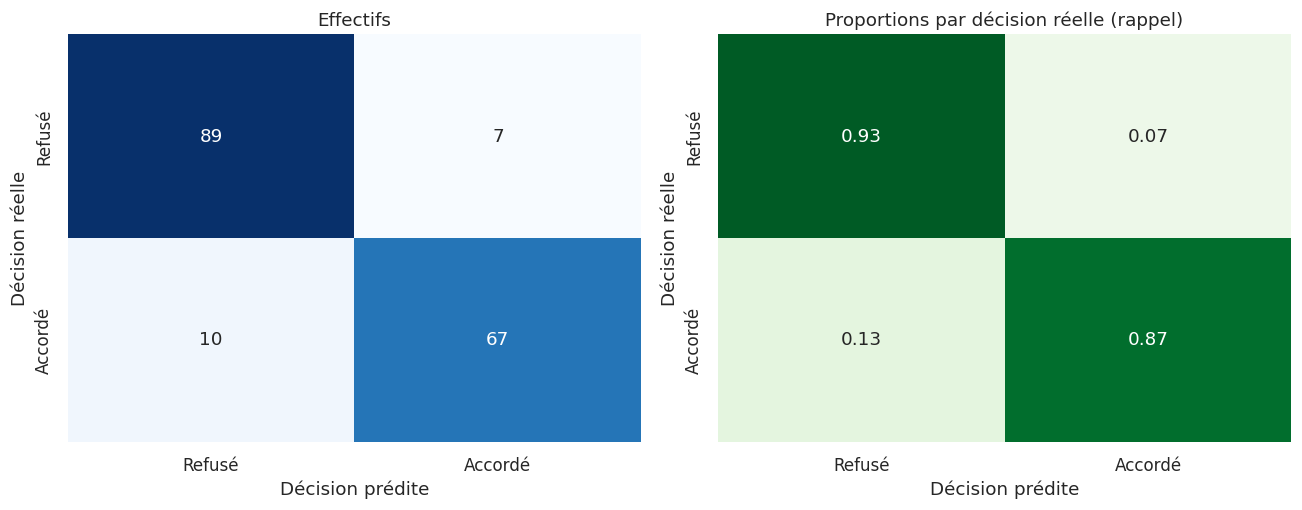

In [36]:
# Matrice de confusion : valeurs absolues et proportions par ligne
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=noms_classes,
            yticklabels=noms_classes, cbar=False, ax=axes[0])
axes[0].set_title("Effectifs")
axes[0].set_xlabel("Décision prédite")
axes[0].set_ylabel("Décision réelle")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=noms_classes,
            yticklabels=noms_classes, vmin=0, vmax=1, cbar=False, ax=axes[1])
axes[1].set_title("Proportions par décision réelle (rappel)")
axes[1].set_xlabel("Décision prédite")
axes[1].set_ylabel("Décision réelle")
plt.tight_layout()
plt.show()

**Ce qu'on observe :** sur 173 demandes, le modèle fait 17 erreurs :

- **7 faux positifs** (crédits risqués accordés) ;
- **10 faux négatifs** (bons clients refusés).

Le modèle retrouve 93 % des refus et 87 % des accords. Pour une banque, les faux positifs sont les erreurs les plus graves.

### 7.2 Courbe ROC et choix du seuil

Par défaut, le modèle accorde le crédit si la probabilité dépasse 0,5. Mais on peut changer ce seuil : un seuil plus haut rend le modèle plus prudent.

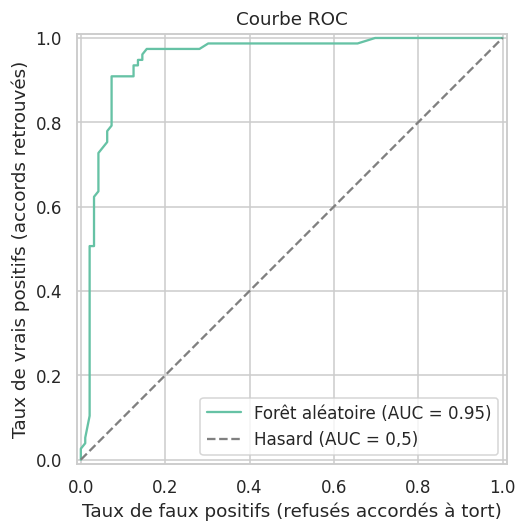

,Seuil,Exactitude,Faux positifs (risque),Faux négatifs (clients perdus)
0,0.3,0.890,17,2
1,0.4,0.896,12,6
2,0.5,0.902,7,10
3,0.6,0.867,6,17
4,0.7,0.838,4,24


In [37]:
# Courbe ROC du meilleur modèle sur le jeu de test
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, y_proba, name=meilleur_nom, ax=ax)
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Hasard (AUC = 0,5)")
ax.set_xlabel("Taux de faux positifs (refusés accordés à tort)")
ax.set_ylabel("Taux de vrais positifs (accords retrouvés)")
ax.set_title("Courbe ROC")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Effet du seuil sur les deux types d'erreur
lignes = []
for seuil in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (y_proba >= seuil).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    lignes.append({"Seuil": seuil, "Exactitude": accuracy_score(y_test, pred),
                   "Faux positifs (risque)": fp, "Faux négatifs (clients perdus)": fn})
pd.DataFrame(lignes).round(3)

**Ce qu'on observe :**

- La courbe ROC est proche du coin en haut à gauche (AUC d'environ 0,95) : le modèle est bon.
- **Plus le seuil est haut, moins il y a de faux positifs, mais plus il y a de faux négatifs.**
- Le choix du seuil est donc une **décision de gestion** : tout dépend de ce qui coûte le plus cher à la banque.

### 7.3 Courbe d'apprentissage

La courbe d'apprentissage montre si le modèle s'améliore quand on lui donne plus de données.

- Si les deux courbes sont basses : le modèle est trop simple (**sous-apprentissage**).
- S'il y a un grand écart entre les deux courbes : le modèle apprend par cœur (**surapprentissage**).

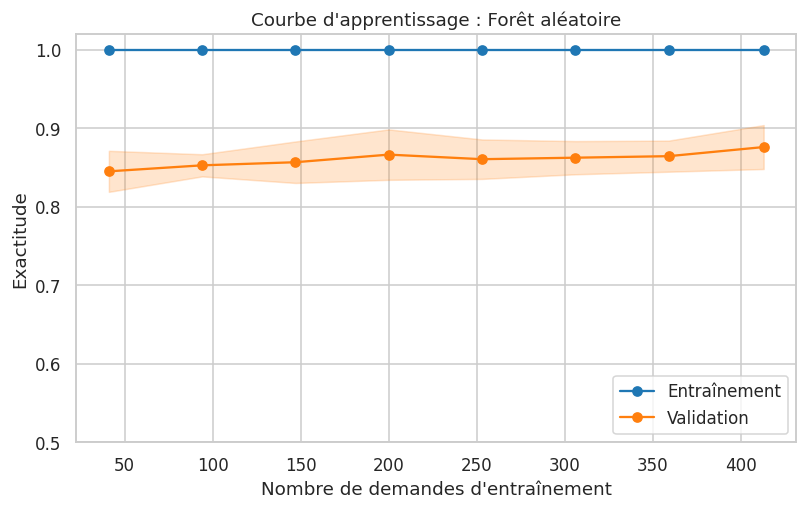

In [38]:
# Courbe d'apprentissage du meilleur modèle
tailles, scores_train, scores_val = learning_curve(
    meilleur_pipe, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8), cv=validation, scoring="accuracy", n_jobs=-1
)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for scores, label, couleur in [(scores_train, "Entraînement", "tab:blue"),
                               (scores_val, "Validation", "tab:orange")]:
    moyenne, ecart = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(tailles, moyenne, "o-", color=couleur, label=label)
    ax.fill_between(tailles, moyenne - ecart, moyenne + ecart, alpha=0.2, color=couleur)
ax.set_xlabel("Nombre de demandes d'entraînement")
ax.set_ylabel("Exactitude")
ax.set_title(f"Courbe d'apprentissage : {meilleur_nom}")
ax.set_ylim(0.5, 1.02)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Ce qu'on observe :**

- Le score d'entraînement est toujours de 1 : la forêt apprend par cœur les données qu'elle voit.
- Le score de validation monte doucement (de 0,85 à 0,88).
- L'écart entre les deux courbes montre un léger **surapprentissage**. Plus de données aideraient encore un peu.

## 8. Interprétation du modèle

### 8.1 Importance des variables

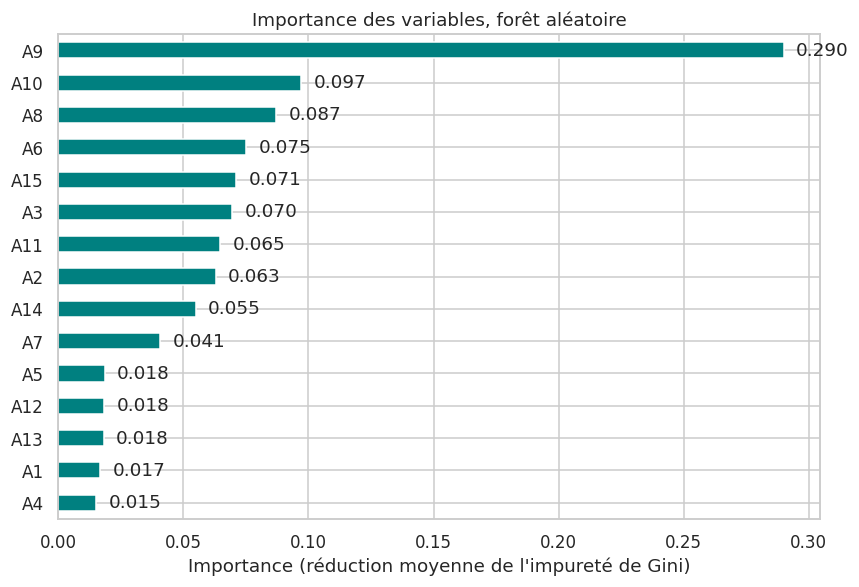

In [39]:
# Importance des variables pour la forêt aléatoire
foret = Pipeline([("prep", preprocesseur),
                  ("modele", RandomForestClassifier(n_estimators=200, random_state=42))])
foret.fit(X_train, y_train)

noms = foret.named_steps["prep"].get_feature_names_out()
noms = [n.replace("num__", "").replace("cat__", "") for n in noms]
importances = pd.Series(foret.named_steps["modele"].feature_importances_, index=noms)

# Regroupement par variable d'origine (A9_t et A9_f -> A9, etc.)
importances_var = importances.groupby(lambda n: n.split("_")[0]).sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
importances_var.plot.barh(ax=ax, color="teal")
for i, val in enumerate(importances_var):
    ax.text(val + 0.005, i, f"{val:.3f}", va="center")
ax.set_xlabel("Importance (réduction moyenne de l'impureté de Gini)")
ax.set_title("Importance des variables, forêt aléatoire")
plt.tight_layout()
plt.show()

**Ce qu'on observe :**

- **A9 est de loin la variable la plus importante** (29 %).
- Ensuite viennent A10 (environ 10 %), puis A8, A6, A15, A3, A11 et A2 (entre 6 et 9 %).
- A1, A4, A5, A12 et A13 ne servent presque à rien.

Attention : cela montre ce que le modèle utilise, pas une relation de cause à effet. Et comme les variables sont anonymes, on ne sait pas ce que A9 représente.

### 8.2 Une règle simple fait-elle aussi bien ?

Puisque A9 est si importante, on teste une règle très simple : **accorder si A9 = t, refuser sinon.**

In [40]:
# Règle à une variable, évaluée sur l'entraînement et sur le test
regle = lambda donnees: (donnees["A9"] == "t").astype(int)

print(f"Règle A9 : exactitude sur l'entraînement = {accuracy_score(y_train, regle(X_train)):.3f}")
print(f"Règle A9 : exactitude sur le test        = {accuracy_score(y_test, regle(X_test)):.3f}")
print(f"{meilleur_nom} : exactitude sur le test = {accuracy_score(y_test, y_pred):.3f}")
print(f"{meilleur_nom} : AUC sur le test        = {roc_auc_score(y_test, y_proba):.3f}")

vn, fp, fn, vp = confusion_matrix(y_test, regle(X_test), labels=[0, 1]).ravel()
print(f"\nRègle A9 sur le test : {fp} faux positifs, {fn} faux négatifs")

Règle A9 : exactitude sur l'entraînement = 0.838
Règle A9 : exactitude sur le test        = 0.908
Forêt aléatoire : exactitude sur le test = 0.902
Forêt aléatoire : AUC sur le test        = 0.949

Règle A9 sur le test : 15 faux positifs, 1 faux négatifs


**Ce qu'on observe :**

- La règle simple obtient 91 % sur le test, **autant que la forêt aléatoire**.
- Mais la règle fait **15 faux positifs**, contre 7 pour la forêt : elle accorde **deux fois plus de crédits risqués**.
- La forêt donne aussi une **probabilité**, ce qui permet de régler le seuil.

Conclusion : il faut toujours comparer un modèle complexe à une règle simple. Ici, la forêt est plus utile car elle limite les erreurs les plus coûteuses.

### 8.3 Frontières de décision

Pour voir comment un modèle sépare les classes, on utilise seulement deux variables (A8 et A11). Chaque zone de couleur correspond à une décision.

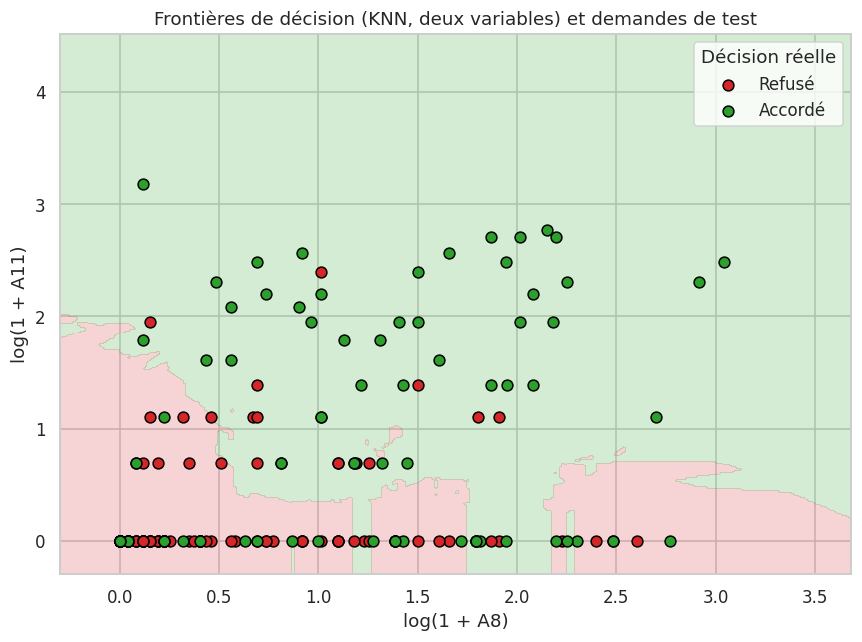

Exactitude du KNN à deux variables sur le test : 0.699


In [41]:
# Frontières de décision avec deux variables : A8 et A11 (échelle log)
deux = ["A8", "A11"]
X2_train = np.log1p(X_train[deux])
X2_test = np.log1p(X_test[deux])

modele_2d = Pipeline([("scaler", StandardScaler()),
                      ("knn", KNeighborsClassifier(n_neighbors=15))])
modele_2d.fit(X2_train, y_train)

x_min, x_max = X2_train[deux[0]].min() - 0.3, X2_train[deux[0]].max() + 0.3
y_min, y_max = X2_train[deux[1]].min() - 0.3, X2_train[deux[1]].max() + 0.3
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grille = pd.DataFrame({deux[0]: xx.ravel(), deux[1]: yy.ravel()})
zz = modele_2d.predict(grille).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], alpha=0.2, colors=["tab:red", "tab:green"])
for valeur, nom, couleur in [(0, "Refusé", "tab:red"), (1, "Accordé", "tab:green")]:
    masque = y_test == valeur
    ax.scatter(X2_test.loc[masque, deux[0]], X2_test.loc[masque, deux[1]],
               label=nom, s=50, color=couleur, edgecolor="k", zorder=3)
ax.set_xlabel("log(1 + A8)")
ax.set_ylabel("log(1 + A11)")
ax.set_title("Frontières de décision (KNN, deux variables) et demandes de test")
ax.legend(title="Décision réelle")
plt.tight_layout()
plt.show()

print(f"Exactitude du KNN à deux variables sur le test : {modele_2d.score(X2_test, y_test):.3f}")

**Ce qu'on observe :** avec seulement A8 et A11, le modèle se trompe souvent (environ 70 % de bonnes réponses, contre 90 % pour le modèle complet). Cela confirme que l'information la plus importante se trouve dans les variables texte comme A9.

## 9. Prédire une nouvelle demande

On utilise le modèle pour évaluer une nouvelle demande inventée. Le pipeline applique automatiquement la même préparation.

In [42]:
# Nouvelle demande fictive, avec sa probabilité d'accord
nouvelle = pd.DataFrame([{
    "A1": "b", "A2": 32.0, "A3": 2.5, "A4": "u", "A5": "g", "A6": "c", "A7": "v",
    "A8": 3.0, "A9": "t", "A10": "t", "A11": 4, "A12": "f", "A13": "g",
    "A14": 120.0, "A15": 500
}])

decision = meilleur_pipe.predict(nouvelle)[0]
proba = meilleur_pipe.predict_proba(nouvelle)[0, 1]
print("Décision prédite :", noms_classes[decision])
print(f"Probabilité d'accord estimée : {proba:.2f}")

# Même dossier, mais avec A9 = f
nouvelle_f = nouvelle.assign(A9="f")
print(f"\nMême dossier avec A9 = f : probabilité d'accord = {meilleur_pipe.predict_proba(nouvelle_f)[0, 1]:.2f}")

Décision prédite : Accordé
Probabilité d'accord estimée : 0.97

Même dossier avec A9 = f : probabilité d'accord = 0.20


**Ce qu'on observe :** le dossier est accordé avec une probabilité de 0,97. Si on change seulement A9 en `f`, la probabilité tombe à 0,20. Cela montre encore le poids de A9.

## 10. Conclusion

**Ce qu'il faut retenir :**

1. C'est un problème d'**apprentissage supervisé** de **classification binaire**.
2. Les étapes : explorer les données, les préparer dans un pipeline, comparer plusieurs modèles à une référence, puis évaluer le meilleur une seule fois sur le test.
3. La **forêt aléatoire** est le meilleur modèle : environ 90 % de bonnes réponses sur le test.
4. L'exactitude ne suffit pas : en crédit, il faut surtout limiter les **faux positifs** (crédits risqués accordés).
5. La variable **A9** porte l'essentiel de l'information.